# Citotox 

- Citoxo analysis in HaCaT cells, for different medium conditions and in presence of Cutibacterium acnes.

In [2]:
import pandas as pd
import numpy as np
import scipy.stats as stats

# Import dataset

In [3]:
import pandas as pd

df = pd.read_csv('/home/marcos/in vitro/citotox/metadata.csv', sep=',', decimal=',')
output_graph = '/home/marcos/Imagens/Resultados/in vitro/citotox/'
df['OD_clean'] = df['OD'].astype(str).str.replace(',', '.').astype(float) # If you date is in the format 0,00 instead of 0.00, you can use this line to convert it to float
display (df)

,NAME,ASSAY,OD,OD_clean
0,DMEM_HaCaT_ANAEROBIOSE_24H,D_H_A_24_1,0.581,0.581
1,DMEM_HaCaT_ANAEROBIOSE_24H,D_H_A_24_2,0.425,0.425
2,DMEM_HaCaT_ANAEROBIOSE_24H,D_H_A_24_3,0.529,0.529
3,RCM_HaCaT_ANAEROBIOSE_24H,R_H_A_24_1,0.242,0.242
4,RCM_HaCaT_ANAEROBIOSE_24H,R_H_A_24_2,0.232,0.232
...,...,...,...,...
94,RCM_HaCaT+C.ACNES_AEROBIOSE_0H,R_HC_O_0_2,0.234,0.234
95,RCM_HaCaT+C.ACNES_AEROBIOSE_0H,R_HC_O_0_3,0.218,0.218
96,LDH_MAX,L_M_1,2.277,2.277
97,LDH_MAX,L_M_2,2.240,2.240


In [4]:
# Calculate the mean OD_clean for the LDH_MAX group
od_med_ldh_max = df[df['NAME'] == 'LDH_MAX']['OD_clean'].mean()

# Create a new column for Percent Cytotoxicity
df['Percent_Cytoxicity'] = 100 * (df['OD_clean'] / od_med_ldh_max)

# Agroup the data by 'NAME' and calculate the mean and standard deviation for OD_clean and Percent_Cytoxicity
results = df.groupby('NAME', as_index=False).agg(
    OD_Med=('OD_clean', 'mean'), #mean
    OD_SD=('OD_clean', 'std'), #standard deviation
    Cytox_Med=('Percent_Cytoxicity', 'mean'),
    Cytox_SD=('Percent_Cytoxicity', 'std'),
    Replicated=('OD_clean', 'count')
)

# 5. Calculte the standard error of the mean (SEM) for Percent Cytotoxicity
results['Cytox_SE'] = results['Cytox_SD'] / (results['Replicated'] ** 0.5)

# Salvar o resultado final
results.to_csv('metadata_citotox_calculated.csv', index=False)

# Visualizar as primeiras linhas do dataframe resultante
results.head()

,NAME,OD_Med,OD_SD,Cytox_Med,Cytox_SD,Replicated,Cytox_SE
0,DMEM_HaCaT+C.ACNES_AEROBIOSE_0H,0.461000,0.044508,20.269676,1.956988,3,1.129867
1,DMEM_HaCaT+C.ACNES_AEROBIOSE_12H,0.559333,0.076970,24.593287,3.384275,3,1.953912
2,DMEM_HaCaT+C.ACNES_AEROBIOSE_24H,0.600667,0.031086,26.410670,1.366814,3,0.789130
3,DMEM_HaCaT+C.ACNES_AEROBIOSE_6H,0.556333,0.025775,24.461381,1.133284,3,0.654302
4,DMEM_HaCaT+C.ACNES_ANAEROBIOSE_0H,0.619333,0.024826,27.231423,1.091575,3,0.630221


Visualize graph of SEM and mean of OD values for each condition.

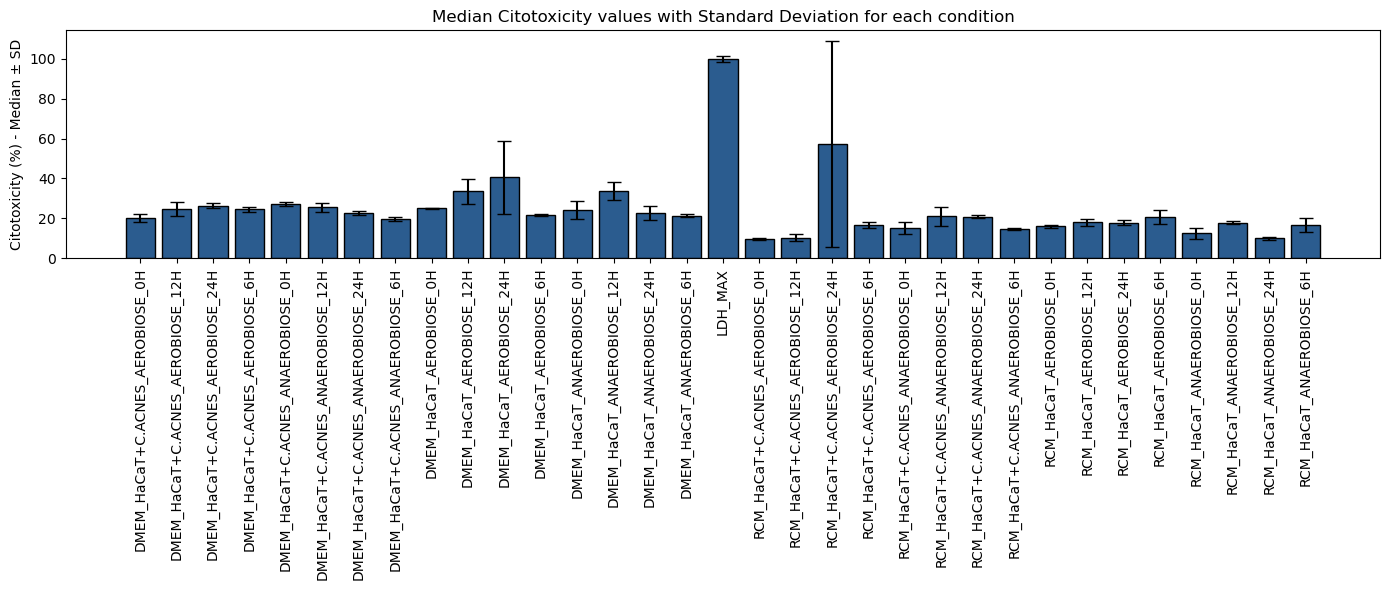

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.pylab

plt.figure(figsize=(14, 6))

plt.bar(
    results['NAME'],
    results['Cytox_Med'],
    yerr=results['Cytox_SD'],
    capsize=5,
    color='#2b5c8f',
    edgecolor='black'
)

plt.xticks(rotation=90)
plt.ylabel('Citotoxicity (%) - Median ± SD')
plt.title('Median Citotoxicity values with Standard Deviation for each condition')
plt.tight_layout()
plt.show()

Normality test

=== Normality per Group (Shapiro-Wilk) ===
Normal Groups (p > 0.05): 31 of 33

=== Global Normality of Residuals ===
Shapiro-Wilk Statistic: 0.4779
p-value: 4.1836e-17
Normal Distribution? No (Non-parametric test recommended)


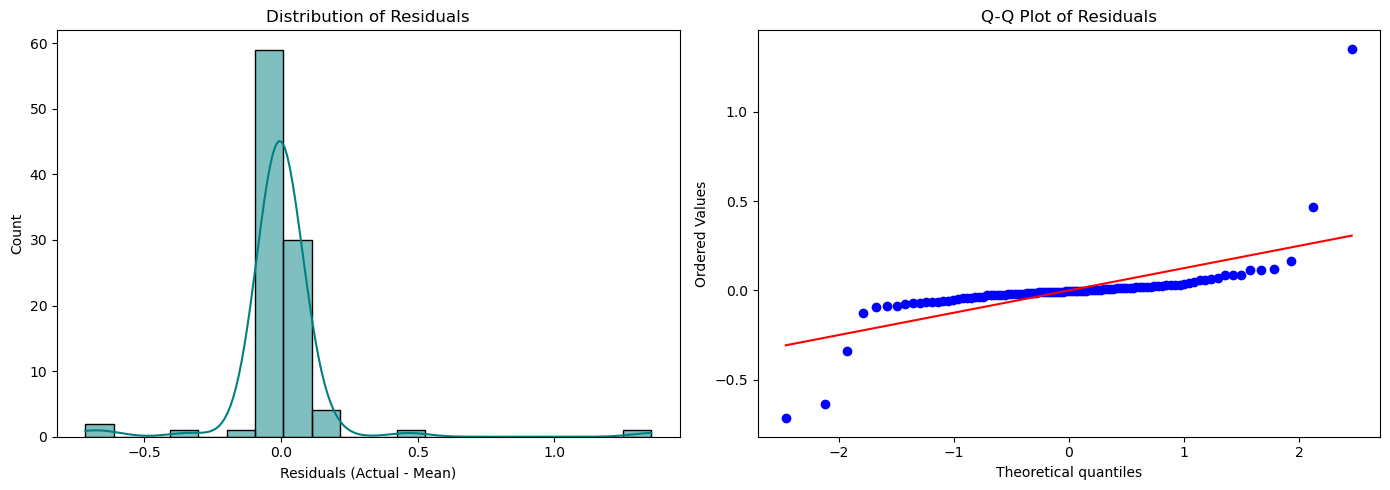

In [6]:
shapiro_results = []

for name, group in df.groupby('NAME'):
    # Shapiro-Wilk
    if len(group['OD_clean']) >= 3:
        stat, p_value = stats.shapiro(group['OD_clean'])
        shapiro_results.append({
            'Tratament': name,
            'Statistical_W': stat,
            'p_valor': p_value,
            'Normal': 'Yes' if p_value > 0.05 else 'No (Recomend test non-parametric)'
        })

df_shapiro = pd.DataFrame(shapiro_results)
print("=== Normality per Group (Shapiro-Wilk) ===")
print(f"Normal Groups (p > 0.05): {sum(df_shapiro['Normal'] == 'Yes')} of {len(df_shapiro)}")

# ========================================================
# ABORDAGEM 2: Teste dos Resíduos (RECOMENDADO para n=3)
# ========================================================
# Calcula o resíduo: Valor real - Média do grupo
df['OD_Media_Grupo'] = df.groupby('NAME')['OD_clean'].transform('mean')
df['residuals'] = df['OD_clean'] - df['OD_Media_Grupo']

# Teste de normalidade em todos os resíduos juntos
stat_res, p_value_res = stats.shapiro(df['residuals'])

print("\n=== Global Normality of Residuals ===")
print(f"Shapiro-Wilk Statistic: {stat_res:.4f}")
print(f"p-value: {p_value_res:.4e}")
print(f"Normal Distribution? {'Yes' if p_value_res > 0.05 else 'No (Non-parametric test recommended)'}")

# ========================================================
# VISUALIZAÇÃO: Q-Q Plot e Histograma dos resíduos
# ========================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# 1. Histograma (Avaliar assimetria)
sns.histplot(df['residuals'], kde=True, ax=ax1, color='teal')
ax1.set_title('Distribution of Residuals')
ax1.set_xlabel('Residuals (Actual - Mean)')

# 2. Q-Q Plot (Os pontos devem seguir a linha vermelha para ser normal)
stats.probplot(df['residuals'], dist="norm", plot=ax2)
ax2.set_title('Q-Q Plot of Residuals')

plt.tight_layout()
plt.show()

Statistical analysis: ANOVA and Dunn's test for multiple comparisons.

In [7]:
!pip install scikit-posthocs
import pandas as pd
import scipy.stats as stats
import scikit_posthocs as sp
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
palette_colors = {
    'DMEM_HaCaT_ANAEROBIOSE_': '#1f77b4',
    'RCM_HaCaT_ANAEROBIOSE_': '#ff7f0e',
    'DMEM_HaCaT+C.ACNES_ANAEROBIOSE_': '#2ca02c',
    'RCM_HaCaT+C.ACNES_ANAEROBIOSE_': '#d62728',
    'DMEM_HaCaT+C.ACNES_AEROBIOSE_': '#9467bd',
    'RCM_HaCaT+C.ACNES_AEROBIOSE_': '#8c564b',
    'DMEM_HaCaT_AEROBIOSE_': "#d300fd",
    'RCM_HaCaT_AEROBIOSE_': "#000000",
    'LDH_MAX': "#ffffff"
}

=== GLOBAL RESULT ===
Kruskal-Wallis (H statistical): 89.4333
global p-valor: 2.4611e-07

There is a statistical difference! Generating Dunn matrix...

--- Significant statistics (p < 0.05) vs LDH_MAX ---
RCM_HaCaT+C.ACNES_AEROBIOSE_0H      0.017080
RCM_HaCaT+C.ACNES_AEROBIOSE_12H     0.017080
RCM_HaCaT_ANAEROBIOSE_0H            0.017080
RCM_HaCaT+C.ACNES_ANAEROBIOSE_6H    0.017080
RCM_HaCaT_ANAEROBIOSE_24H           0.017080
RCM_HaCaT+C.ACNES_ANAEROBIOSE_0H    0.024950
RCM_HaCaT_AEROBIOSE_0H              0.027402
RCM_HaCaT+C.ACNES_AEROBIOSE_6H      0.034022
RCM_HaCaT_ANAEROBIOSE_6H            0.039551
Name: LDH_MAX, dtype: float64


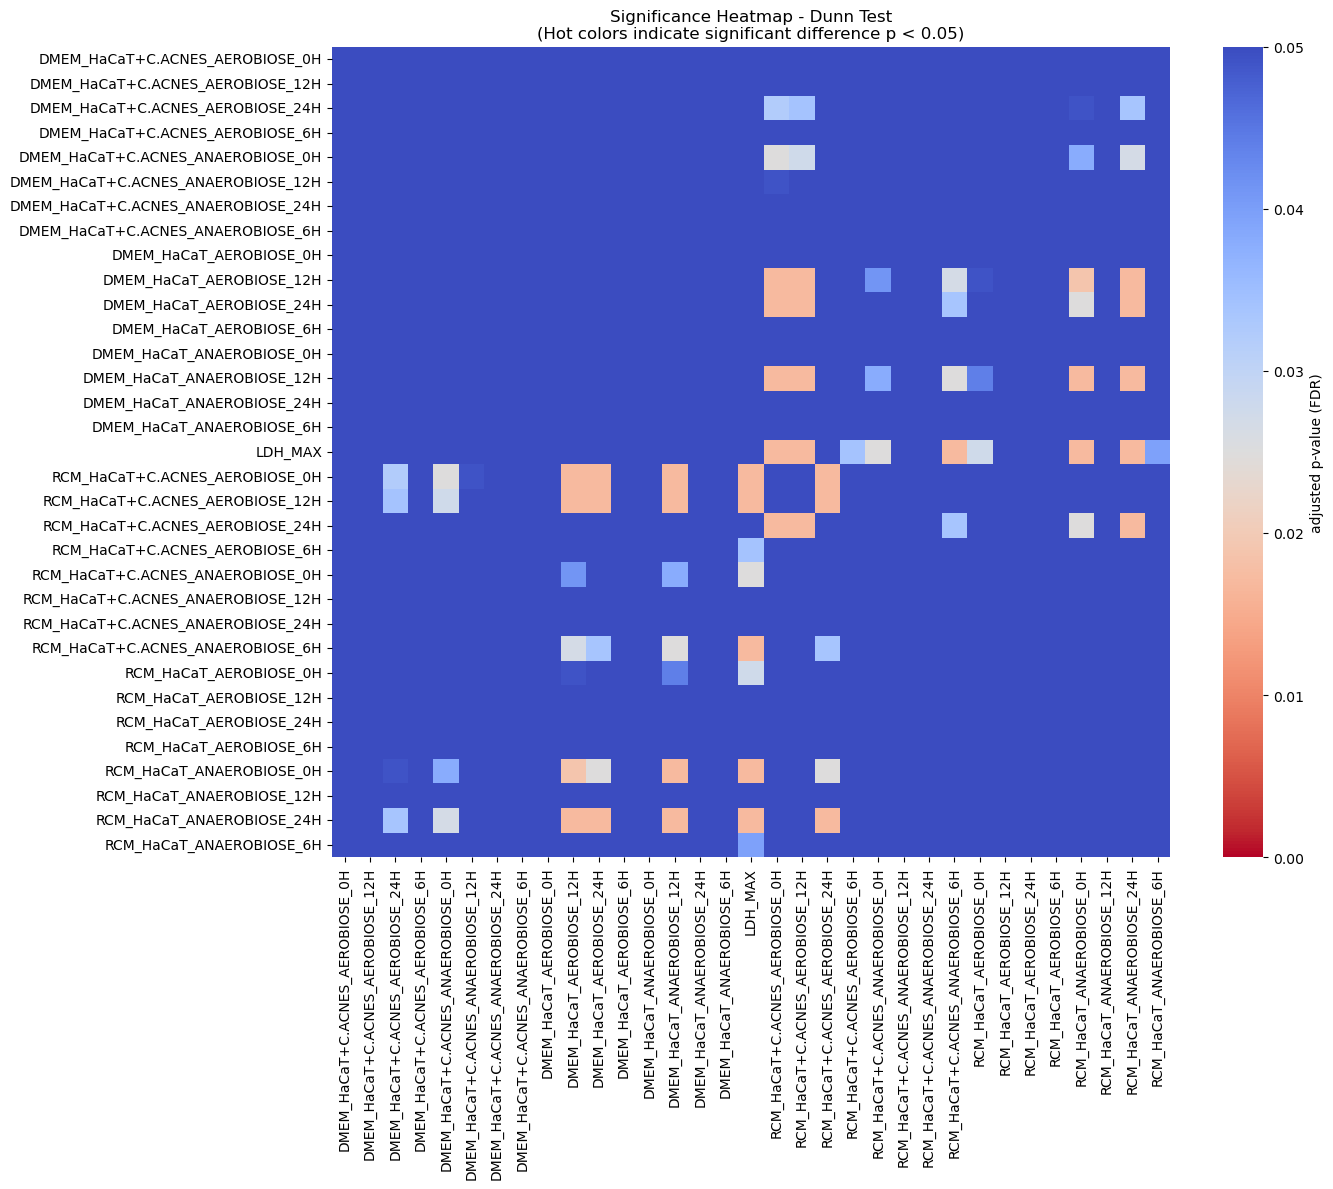

In [9]:
date_groups = [group['OD_clean'].values for name, group in df.groupby('NAME')]
stat_kw, p_valor_kw = stats.kruskal(*date_groups)

print("=== GLOBAL RESULT ===")
print(f"Kruskal-Wallis (H statistical): {stat_kw:.4f}")
print(f"global p-valor: {p_valor_kw:.4e}")

if p_valor_kw < 0.05:
    print("\nThere is a statistical difference! Generating Dunn matrix...\n")
    
    # 3. Teste de Dunn com ajuste FDR (Benjamini-Hochberg)
    df_dunn = sp.posthoc_dunn(
        df, 
        val_col='OD_clean', 
        group_col='NAME', 
        p_adjust='fdr_bh'
    )
    
    # Opcional: I use the LDH_MAX as control to see which groups are significantly different from it 
    control = 'LDH_MAX' 
    print(f"--- Significant statistics (p < 0.05) vs {control} ---")
    
    if control in df_dunn.columns:
        # Filtra apenas o que deu p-valor menor que 0.05 e ordena do mais forte para o mais fraco
        sig_vs_control = df_dunn[control][df_dunn[control] < 0.05].sort_values()
        print(sig_vs_control)
    else:
        print("Control group not found.")

    # 4. Visualização: Heatmap dos p-valores
    # Cria uma máscara para mostrar apenas o que é estatisticamente significativo (p < 0.05)
    plt.figure(figsize=(14, 12))
    sns.heatmap(
        df_dunn, 
        cmap='coolwarm_r', 
        vmin=0, 
        vmax=0.05,  # Tudo o que for p > 0.05 ficará com a cor máxima (cinza/azul claro)
        cbar_kws={'label': 'adjusted p-value (FDR)'},
        xticklabels=True, 
        yticklabels=True
    )
    plt.title("Significance Heatmap - Dunn Test\n(Hot colors indicate significant difference p < 0.05)")
    plt.tight_layout()
    plt.show()

else:
    print("\nConclusion: There was no statistical difference between the groups (P > 0.05).")

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
import scikit_posthocs as sp
import re
import os

output_path: /home/marcos/Imagens/Resultados/in vitro/citotox/cytox_HaCaT.png
output_path: /home/marcos/Imagens/Resultados/in vitro/citotox/cytox_HaCaT.svg
output_path: /home/marcos/Imagens/Resultados/in vitro/citotox/cytox_HaCaT.pdf


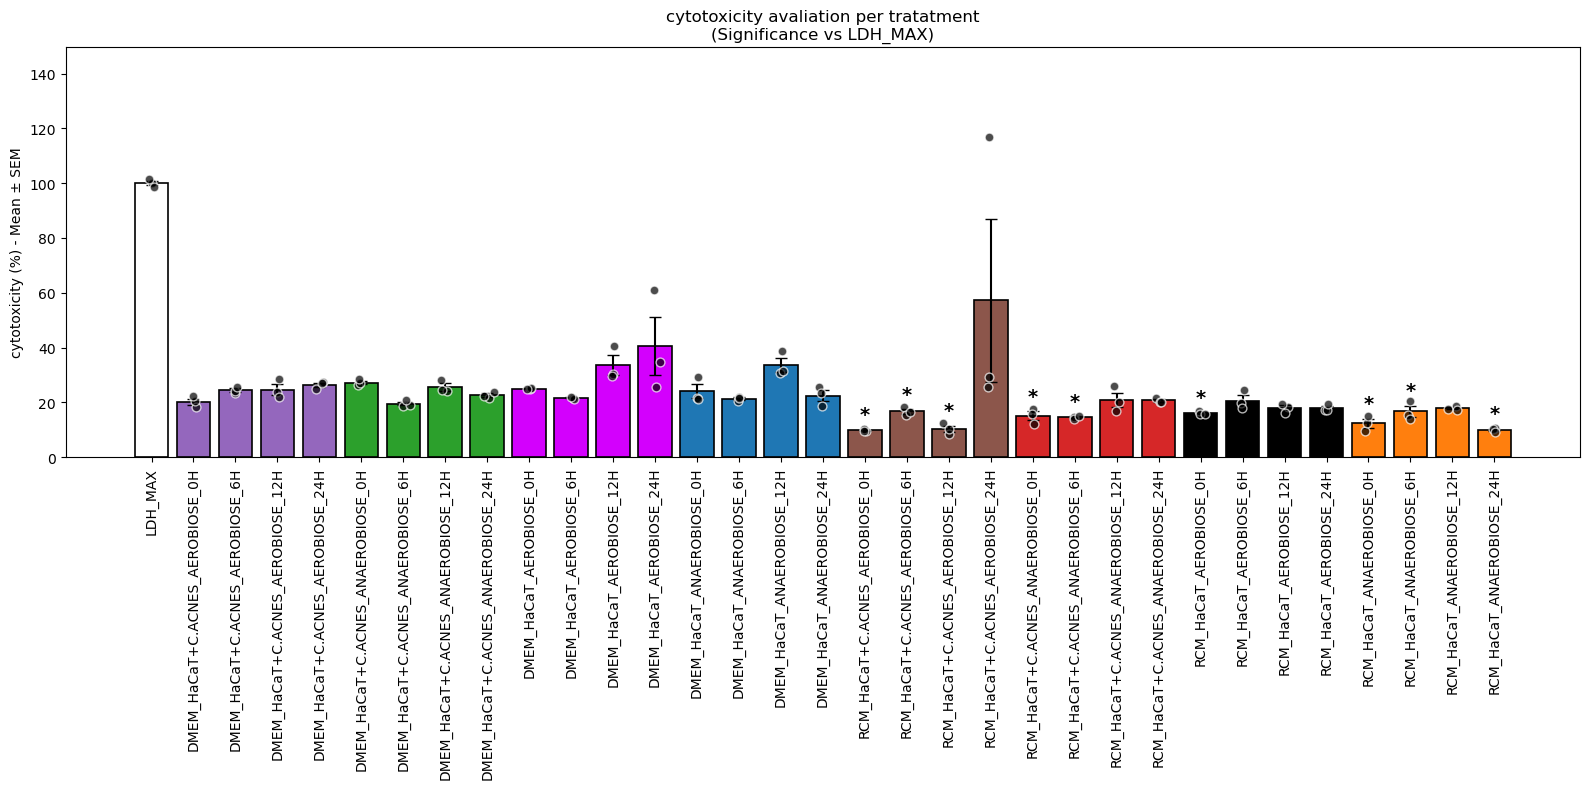

Graph of HaCaT cell cytotoxicity under different treatment conditions: Anaerobiosis, aerobiosis, presence or absence of Cutibacterium acnes at OD600 0.1. The calculation was based on the manufacturer's standards. The bars represent the mean ± SEM, the symbols indicate a statistically significant difference compared to the {control} (Kruskal-Wallis test followed by Dunn's post-hoc test with FDR adjustment; *p<0.005, **p<0.01, ***p<0.0001).


In [11]:
def ordened(s):
    return [int(texto) if texto.isdigit() else texto.lower() for texto in re.split(r'(\d+)', s)]

results = df.groupby('NAME', as_index=False).agg(
    Cytox_Mean=('Percent_Cytoxicity', 'mean'),
    Cytox_SD=('Percent_Cytoxicity', 'std'),
    Replicated=('Percent_Cytoxicity', 'count')
)
results['Cytox_SE'] = results['Cytox_SD'] / np.sqrt(results['Replicated'])
# Ordenation of the groups in a natural way (0H, 6H, 12H, 24H)
control = 'LDH_MAX'

df_control = results[results['NAME'] == control]
df_others = results[results['NAME'] != control].copy()

df_others = df_others.sort_values(by='NAME', key=lambda x: x.map(ordened))

results = pd.concat([df_control, df_others]).reset_index(drop=True)
# ========================================================
def obtain_colors(complete_name, pallete):
    for key, color in pallete.items():
        if key in complete_name:
            return color
    return '#5c8a8a'  # Default color if no match is found
# Statiscal analysis: Dunn's Test
df_dunn = sp.posthoc_dunn(df, val_col='Percent_Cytoxicity', group_col='NAME', p_adjust='fdr_bh')
plt.figure(figsize=(16, 8))
x_pos = np.arange(len(results))
plt.bar(
    x_pos, 
    results['Cytox_Mean'], 
    yerr=results['Cytox_SE'], 
    capsize=4, 
    color= [obtain_colors(name, palette_colors) for name in results['NAME']],
    edgecolor='black',
    linewidth=1.2
)
max_weight = results['Cytox_Mean'] + results['Cytox_SE']
for i, name in enumerate(results['NAME']):
    if name != control and control in df_dunn.columns:
        p_val = df_dunn.loc[name, control]
     
        if p_val < 0.001:
            sig_symbol = '***'
        elif p_val < 0.01:
            sig_symbol = '**'
        elif p_val < 0.05:
            sig_symbol = '*'
        else:
            sig_symbol = ''
            
        if sig_symbol:
            plt.text(
                x_pos[i], 
                max_weight.iloc[i] + 2, 
                sig_symbol, 
                ha='center', 
                va='bottom', 
                fontsize=14, 
                fontweight='bold'
            )
map_pos = {name: i for i, name in enumerate(results['NAME'])}

for name, grupo in df.groupby('NAME'):
    if name in map_pos:
        x_base = map_pos[name]
      
        y_values = grupo['Percent_Cytoxicity'] 
        
        x_jitter = np.random.normal(x_base, 0.05, size=len(y_values))
       
        plt.scatter(
            x_jitter, 
            y_values, 
            color='black',  
            alpha=0.7,      
            edgecolor='white', 
            zorder=3, 
            s=40          
        )
plt.xticks(x_pos, results['NAME'], rotation=90)
plt.ylabel('cytotoxicity (%) - Mean ± SEM')
plt.title(f'cytotoxicity avaliation per tratatment\n(Significance vs {control})')
plt.ylim(0, results['Cytox_Mean'].max() + results['Cytox_SE'].max() + 20) 
plt.tight_layout()
fmt= ['png', 'svg', 'pdf']

for f in fmt:
    output_path = os.path.join(output_graph, f"cytox_HaCaT.{f}")
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    print('output_path:', output_path)

plt.show()

print("Graph of HaCaT cell cytotoxicity under different treatment conditions: Anaerobiosis, aerobiosis, presence or absence of Cutibacterium acnes at OD600 0.1. The calculation was based on the manufacturer's standards. The bars represent the mean ± SEM, the symbols indicate a statistically significant difference compared to the {control} (Kruskal-Wallis test followed by Dunn's post-hoc test with FDR adjustment; *p<0.005, **p<0.01, ***p<0.0001).")

Delta citotoxicity analysis: Calculate the difference in cytotoxicity between each condition and the control (medium only) and visualize the results.

output_path: /home/marcos/Imagens/Resultados/in vitro/citotox/delta_cytox_HaCaT.png
output_path: /home/marcos/Imagens/Resultados/in vitro/citotox/delta_cytox_HaCaT.svg
output_path: /home/marcos/Imagens/Resultados/in vitro/citotox/delta_cytox_HaCaT.pdf


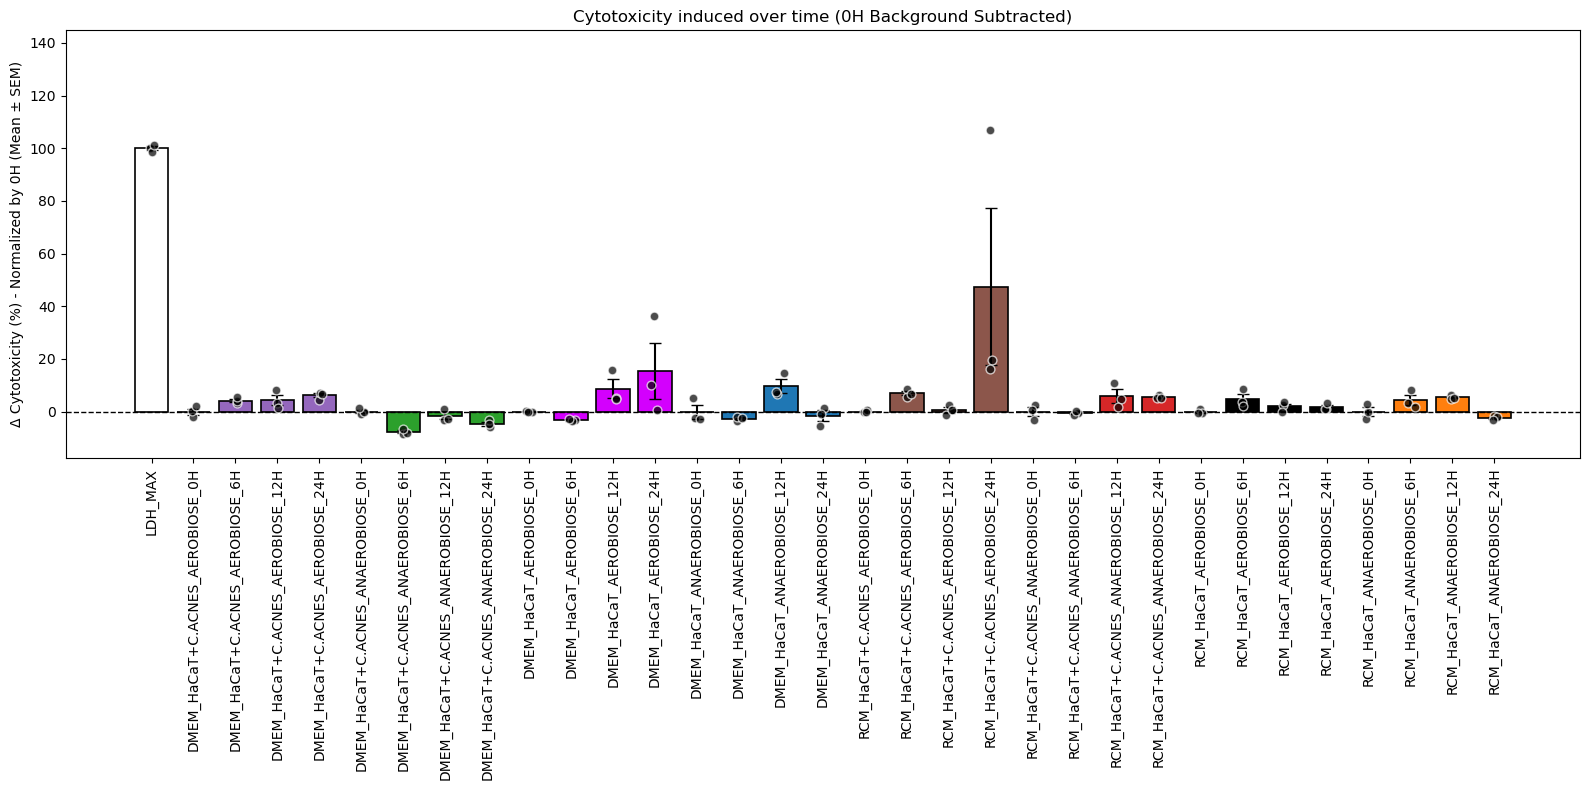

output_path: /home/marcos/Imagens/Resultados/in vitro/citotox/delta_cytox_HaCaT.pdf
Graph of HaCaT cell cytotoxicity under different treatment conditions: Anaerobiosis, aerobiosis, presence or absence of Cutibacterium acnes at OD600 0.1. The calculation was done by subtracting the 0H time mean for each treatment group. The bars represent the mean ± SEM, and the individual points show the variation among replicates.


In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
import os # Added os import since it's used at the end

# Function for natural sorting of names (0H, 6H, 12H, 24H)
def natural_sort(s):
    return [int(text) if text.isdigit() else text.lower() for text in re.split(r'(\d+)', s)]

# 3. Map the '0H' time means for each treatment group
# (We will take everything before '_0H' to identify the base group)
zero_h_means = {}
for name, group in df.groupby('NAME'):
    if name.endswith('_0H'):
        base_name = re.sub(r'_0H$', '', name) # Remove the end to extract the base
        zero_h_means[base_name] = group['Percent_Cytoxicity'].mean()

# 4. Create function to subtract the background (0H) from each sample
def subtract_background(row):
    name = row['NAME']
    
    # If it is LDH_MAX, do not change the value
    if name == 'LDH_MAX':
        return row['Percent_Cytoxicity']
        
    # Extracts the base name (removing the time suffix)
    base_name = re.sub(r'_\d+H$', '', name)
    
    # If we find the 0H mean for this base group, subtract
    if base_name in zero_h_means:
        return row['Percent_Cytoxicity'] - zero_h_means[base_name]
        
    return row['Percent_Cytoxicity']

# Apply the function to create the Delta column (Cytotoxicity Variation)
df['Delta_Cytoxicity'] = df.apply(subtract_background, axis=1)

# 5. Group and calculate statistics for the NEW metric (Delta)
results = df.groupby('NAME', as_index=False).agg(
    Delta_Mean=('Delta_Cytoxicity', 'mean'),
    Delta_Std=('Delta_Cytoxicity', 'std'),
    Replicates=('Delta_Cytoxicity', 'count')
)
results['Delta_StdError'] = results['Delta_Std'] / np.sqrt(results['Replicates'])

# 6. Intelligent Sorting
control = 'LDH_MAX'
df_control = results[results['NAME'] == control]
df_others = results[results['NAME'] != control].copy()
df_others = df_others.sort_values(by='NAME', key=lambda x: x.map(natural_sort))
results = pd.concat([df_control, df_others]).reset_index(drop=True)
#---------------------------------------------------------------
def obtain_colors(complete_name, pallete):
    for key, color in pallete.items():
        if key in complete_name:
            return color
    return '#5c8a8a'  # Default color if no match is found
# 7. Create the Bar Chart with normalized values
plt.figure(figsize=(16, 8))
x_pos = np.arange(len(results))

plt.bar(
    x_pos, 
    results['Delta_Mean'], 
    yerr=results['Delta_StdError'], 
    capsize=4, 
    color= [obtain_colors(name, palette_colors) for name in results['NAME']],
    edgecolor='black',
    linewidth=1.2
)
# ========================================================
# CODE TO ADD THE DOTS (INDIVIDUAL)
# ========================================================
# Creates a dictionary to know exactly the X position of each bar
map_pos = {name: i for i, name in enumerate(results['NAME'])}

# Takes the original data (df) and draws each dot
for name, group in df.groupby('NAME'):
    if name in map_pos:
        x_base = map_pos[name]
        
        # The metric you are plotting (use 'Percent_Cytoxicity' if it's the normal chart)
        y_values = group['Delta_Cytoxicity'] 
        
        # Creates a small horizontal deviation (jitter) so the dots don't overlap
        x_jitter = np.random.normal(x_base, 0.05, size=len(y_values))
        
        # Plots the points (s=size, zorder=3 ensures they are in front of the bars)
        plt.scatter(
            x_jitter, 
            y_values, 
            color='black',  # Dot color
            alpha=0.7,      # Transparency (0 to 1)
            edgecolor='white', # Little white border to highlight
            zorder=3, 
            s=40          # Dot size
        )
# ========================================================

# Add a dashed line at 0 (since now we can have negative or zero values)
plt.axhline(0, color='black', linestyle='--', linewidth=1)

plt.xticks(x_pos, results['NAME'], rotation=90)
plt.ylabel('Δ Cytotoxicity (%) - Normalized by 0H (Mean ± SEM)')
plt.title('Cytotoxicity induced over time (0H Background Subtracted)')

# Adds a dynamic limit to the Y axis so as not to cut the bars
plt.ylim(results['Delta_Mean'].min() - 10, results['Delta_Mean'].max() + results['Delta_StdError'].max() + 15)

plt.tight_layout()
fmt= ['png', 'svg', 'pdf']

for f in fmt:
    output_path = os.path.join(output_graph, f"delta_cytox_HaCaT.{f}")
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    print('output_path:', output_path)
plt.show()
print('output_path:', output_path)
print("Graph of HaCaT cell cytotoxicity under different treatment conditions: Anaerobiosis, aerobiosis, presence or absence of Cutibacterium acnes at OD600 0.1. The calculation was done by subtracting the 0H time mean for each treatment group. The bars represent the mean ± SEM, and the individual points show the variation among replicates.")

## Growth analysis
For the bacterial growth analysis, I use OD 600 metrics. 
In excel plotted the growth curves and calculated OD corrected (substracting the mean of the blank), and next substracted the mean of the HaCaT lecture. 

In [13]:
!pip install --upgrade pip
!pip install statannotations seaborn

In [14]:
# Change growth table
import pandas as pd

# Read without header and as text: the file has stacked blocks and decimal commas
raw = pd.read_csv("/home/marcos/in vitro/citotox/growth/growth_data.csv", header=None, dtype=str)
output = '/home/marcos/in vitro/citotox/growth'

# Exp 1: sample_cols = ["C1", "C2", "C3", "C4", "C5", "CA1", "CA2", "CA3", "CA4", "CA5", "CA6"]
sample_cols = ["A1", "A2", "A3"]

records = []
current_time = None

for _, row in raw.iterrows():
    first = row.iloc[0]

    # Skip empty separator rows and the repeated header rows
    if pd.isna(first) or first == "medium":
        continue

    # Rows like "0h", "6h"... define the time of the following block
    if first.endswith("h") and first[:-1].isdigit():
        current_time = int(first[:-1])
        continue

    # Otherwise it's a medium row: one record per sample
    for sample, value in zip(sample_cols, row.iloc[1:]):
        records.append({
            "time_h": current_time,
            "medium": first,
            "sample": sample,
            "od": float(value.replace(",", ".")),  # decimal comma -> point
        })

tidy = pd.DataFrame(records)
tidy.head(12)
tidy.tail(12)
display(tidy)

,time_h,medium,sample,od
0,0,RCM,A1,-0.005
1,0,RCM,A2,0.002
2,0,RCM,A3,-0.001
3,0,DMEM,A1,0.008
4,0,DMEM,A2,0.000
...,...,...,...,...
91,24,RCM+HaCaT_anaerobic,A2,0.034
92,24,RCM+HaCaT_anaerobic,A3,0.069
93,24,DMEM+HaCaT_anaerobic,A1,-0.066
94,24,DMEM+HaCaT_anaerobic,A2,0.033


In [15]:
# Definig the colors for each medium
colors = {
    'RCM': '#1f77b4',        # Azul
    'DMEM': '#ff7f0e',            # Laranja
    'RCM_anaerobic': '#2ca02c',      # Verde
    'DMEM_anaerobic': '#d62728', # Vermelho
    'DMEM+HaCaT': '#9467bd', # Roxo
    'RCM+HaCaT': '#8c564b', # Marrom
    'DMEM+HaCaT': '#9467bd', # Roxo
    'RCM+HaCaT_anaerobic': '#8c564b', # Marrom
    'DMEM+HaCaT_anaerobic': '#e377c2'  # Rosa
}

In [16]:
# Mean and standard deviation of the corrected OD for each medium and time
summary = (
    tidy
    .groupby(["medium", "time_h"])["od"]
    .agg(mean="mean", sd="std", n="count")
    .reset_index()
)

summary

,medium,time_h,mean,sd,n
0,DMEM,0,0.002000,0.005292,3
1,DMEM,6,0.049333,0.023180,3
2,DMEM,12,0.046667,0.017954,3
3,DMEM,24,0.119667,0.037873,3
4,DMEM+HaCaT,0,0.003667,0.003055,3
5,DMEM+HaCaT,6,0.028000,0.007810,3
6,DMEM+HaCaT,12,0.031667,0.017786,3
7,DMEM+HaCaT,24,0.043667,0.003786,3
8,DMEM+HaCaT_anaerobic,0,0.036000,0.002646,3
9,DMEM+HaCaT_anaerobic,6,0.026667,0.001528,3


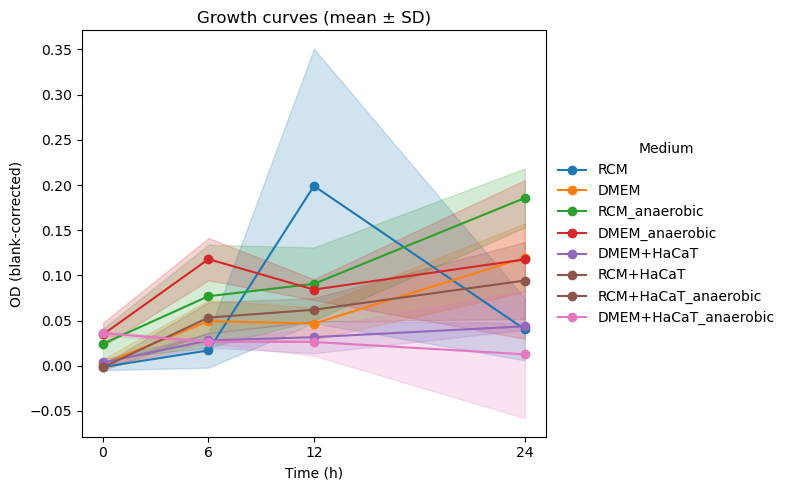

Graph of growth curves for different media over time. The lines represent the mean OD (blank-corrected) and the shaded areas represent the standard deviation (SD) for each medium. The legend indicates the corresponding medium for each curve.


In [17]:
import matplotlib.pyplot as plt
from pathlib import Path


fig, ax = plt.subplots(figsize=(8, 5))

for medium, color in colors.items():
    d = summary[summary["medium"] == medium].sort_values("time_h")

    # Mean curve
    ax.plot(d["time_h"], d["mean"], marker="o", color=color, label=medium)

    # Shaded band: mean ± SD
    ax.fill_between(
        d["time_h"],
        d["mean"] - d["sd"],
        d["mean"] + d["sd"],
        color=color,
        alpha=0.2,
    )

ax.set_xticks(sorted(summary["time_h"].unique()))  # only the measured times
ax.set_xlabel("Time (h)")
ax.set_ylabel("OD (blank-corrected)")
ax.set_title("Growth curves (mean ± SD)")
ax.legend(title="Medium",
          frameon=False,
          loc="center left",
          bbox_to_anchor=(1, 0.5))  # legend outside the plot
output_dir = Path(output)   # your predefined folder
formats = ["png", "pdf", "svg"]   # add or remove formats here

for fmt in formats:
    fig.savefig(
        output_dir / f"growth_curves.{fmt}",
        dpi=300,                  # only affects png/tiff
        bbox_inches="tight",
    )
fig.tight_layout()
plt.show()
print('Graph of growth curves for different media over time. The lines represent the mean OD (blank-corrected) and the shaded areas represent the standard deviation (SD) for each medium. The legend indicates the corresponding medium for each curve.')

## Normality test

In [18]:
# Shapiro-Wilk test for normality (medium vs time)
from scipy import stats

rows = []

for (t, m), d in tidy.groupby(["time_h", "medium"]):
    w, p = stats.shapiro(d["od"])
    rows.append({"time_h": t, "medium": m, "n": len(d), "W": w, "p": p})

normality = pd.DataFrame(rows)
normality["normal"] = normality["p"] > 0.05

normality[~normality["normal"]]   # show only the groups that fail

,time_h,medium,n,W,p,normal
11,6,DMEM_anaerobic,3,0.768282,0.040833,False
28,24,RCM,3,0.762496,0.027796,False


In [19]:
# Homogeneity of variance test (Levene's test) for each time point
rows = []

for t, d in tidy.groupby("time_h"):
    groups = [g["od"].values for _, g in d.groupby("medium")]
    stat, p = stats.levene(*groups, center="median")   # median = robust version (Brown-Forsythe)
    rows.append({"time_h": t, "levene_p": p})

variance_check = pd.DataFrame(rows)
variance_check["equal_var"] = variance_check["levene_p"] > 0.05

variance_check

,time_h,levene_p,equal_var
0,0,0.472739,True
1,6,0.544970,True
2,12,0.340504,True
3,24,0.764038,True


In [20]:
print("Media defined in colors:")
print(list(colors.keys()))

print("\nMedia available in summary:")
print(summary["medium"].unique())

print("\nMissing media:")
print(set(colors.keys()) - set(summary["medium"].unique()))

Media defined in colors:
['RCM', 'DMEM', 'RCM_anaerobic', 'DMEM_anaerobic', 'DMEM+HaCaT', 'RCM+HaCaT', 'RCM+HaCaT_anaerobic', 'DMEM+HaCaT_anaerobic']

Media available in summary:
<StringArray>
[                'DMEM',           'DMEM+HaCaT', 'DMEM+HaCaT_anaerobic',
       'DMEM_anaerobic',                  'RCM',            'RCM+HaCaT',
 'RCM+HaCaT_anaerobic ',        'RCM_anaerobic']
Length: 8, dtype: str

Missing media:
{'RCM+HaCaT_anaerobic'}


In [21]:
import itertools
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats

alpha = 0.05
media = list(colors)


def compact_letters(names, means, p_matrix, alpha=0.05):
    """Give the same letter to groups that are NOT significantly different."""
    order = sorted(range(len(names)), key=lambda k: -means[k])   # highest mean first
    cols = [set(range(len(names)))]                              # start: all groups share one letter

    for a, b in itertools.combinations(range(len(names)), 2):
        if p_matrix[a, b] < alpha:                               # a and b differ: they can't share a letter
            new = []
            for c in cols:
                if a in c and b in c:
                    new += [c - {a}, c - {b}]                    # split the column in two
                else:
                    new.append(c)
            # drop empty, duplicated and contained columns
            cols = [
                c for k, c in enumerate(new)
                if c and not any((c < d) or (c == d and k > j) for j, d in enumerate(new) if j != k)
            ]

    rank = {g: r for r, g in enumerate(order)}
    cols.sort(key=lambda c: min(rank[g] for g in c))             # letter 'a' -> highest-mean group

    letters = {g: "" for g in range(len(names))}
    for letter, c in zip("abcdefghij", cols):
        for g in c:
            letters[g] += letter
    return {names[g]: letters[g] for g in letters}

summary['medium'] = summary['medium'].str.strip()  # Remove leading/trailing whitespace from medium names
means = summary.pivot(index="time_h", columns="medium", values="mean")[media]
sds = summary.pivot(index="time_h", columns="medium", values="sd")[media]
times = means.index.tolist()

# ANOVA is implicit in Tukey HSD: one test per time point, all media vs all media
letters = {}
for t in times:
    d = tidy[tidy["time_h"] == t]
    groups = [d.loc[d["medium"] == m, "od"].values for m in media]
    tukey = stats.tukey_hsd(*groups)
    letters[t] = compact_letters(media, [g.mean() for g in groups], tukey.pvalue, alpha)

x = np.arange(len(times))
n = len(colors)
width = 0.8 / n
rng = np.random.default_rng(0)

fig, ax = plt.subplots(figsize=(11, 5))

for i, (medium, color) in enumerate(colors.items()):
    offset = (i - (n - 1) / 2) * width

    ax.bar(
        x + offset, means[medium], width,
        yerr=sds[medium], capsize=2,
        color=color, alpha=0.6, label=medium,
    )

    for xi, t in zip(x, times):
        pts = tidy[(tidy["medium"] == medium) & (tidy["time_h"] == t)]["od"]
        jitter = rng.uniform(-width * 0.25, width * 0.25, size=len(pts))
        ax.scatter(
            xi + offset + jitter, pts,
            s=12, color=color, edgecolor="black", linewidth=0.5, zorder=3,
        )

        # Significance letter above the highest element (error bar or dot)
        top = max(means.loc[t, medium] + sds.loc[t, medium], pts.max())
        ax.text(xi + offset, top + 0.03, letters[t][medium],
                ha="center", va="bottom", fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels([f"{t}h" for t in times])
ax.set_xlabel("Time")
ax.set_ylabel("OD (blank-corrected)")
ax.set_title("OD by medium and time (mean ± SD, dots = replicates)")
ax.legend(title="Medium", frameon=False, ncol=2, loc="upper left")
ax.set_ylim(0, ax.get_ylim()[1] * 1.05)    # room for the letters

fig.text(
    0.01, 0.01,
    "Letters compare media within each time point (ANOVA + Tukey HSD, p < 0.05). "
    "Different letters = significant difference.",
    fontsize=8,
)

fig.tight_layout(rect=(0, 0.04, 1, 1))     # leaves space for the footnote

# Save after the layout is final
output_dir = Path(output)
for fmt in ["png", "pdf", "svg"]:
    fig.savefig(output_dir / f"growth_bars.{fmt}", dpi=300, bbox_inches="tight")

plt.show()

ValueError: Input sample size must be greater than one.

In [ ]:
for t in sorted(tidy["time_h"].unique()):
    d = tidy[tidy["time_h"] == t]

    print(f"\nTime = {t}")

    for m in media:
        n = (d["medium"] == m).sum()
        print(f"  {m}: n={n}")


Time = 0
  RCM: n=3
  DMEM: n=3
  RCM_anaerobic: n=3
  DMEM_anaerobic: n=3
  DMEM+HaCaT: n=3
  RCM+HaCaT: n=3
  RCM+HaCaT_anaerobic: n=0
  DMEM+HaCaT_anaerobic: n=3

Time = 6
  RCM: n=3
  DMEM: n=3
  RCM_anaerobic: n=3
  DMEM_anaerobic: n=3
  DMEM+HaCaT: n=3
  RCM+HaCaT: n=3
  RCM+HaCaT_anaerobic: n=0
  DMEM+HaCaT_anaerobic: n=3

Time = 12
  RCM: n=3
  DMEM: n=3
  RCM_anaerobic: n=3
  DMEM_anaerobic: n=3
  DMEM+HaCaT: n=3
  RCM+HaCaT: n=3
  RCM+HaCaT_anaerobic: n=0
  DMEM+HaCaT_anaerobic: n=3

Time = 24
  RCM: n=3
  DMEM: n=3
  RCM_anaerobic: n=3
  DMEM_anaerobic: n=3
  DMEM+HaCaT: n=3
  RCM+HaCaT: n=3
  RCM+HaCaT_anaerobic: n=0
  DMEM+HaCaT_anaerobic: n=3
